# Function 1 — Week 6: investigating signal activity

**Question under review:** can strong negative readings guide a useful search for a nearby positive maximum? The course's contamination-source analogy motivates treating response magnitude as evidence of activity. It does not supply a sign-change rule, a distance-to-source law or a guarantee that a strong negative region contains a better positive score.

This notebook tests a narrower claim: **does ignoring sign pull the proposed query towards the centre of the input square?** It compares the same three declared target rules on the same data and candidate locations, then quantifies the movement. The comparison run preserved the then-prepared eight-line file and the existing Week 6 model notebooks; the subsequent agreed decision is recorded below. No query is submitted or evaluated.

[Reading report](../activity-hypothesis.md) · [Earlier magnitude study](../../Week_05/report.md)


## Subsequent agreed decision

Use **`0.537942-0.522217`**, the saved signed-log mean maximum, to follow through on the central-region **hunch**. **None of the outputs so far is regarded as clearly non-zero in practical or source-detection terms.** Floating-point non-zero values are preserved; no background or detection threshold has been established.

The prepared file has now been updated for Function 1; nothing has been submitted. The executed comparison below retains the original signed-UCB proposal as its reference. Its numerical outputs and hashes record that earlier comparison run, not the later file revision.

In [1]:
%matplotlib inline
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "1"
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

root = next(p for p in Path.cwd().parents if (p / "run-python.ps1").is_file())
expected = root / ".venv/Scripts/python.exe"
if Path(sys.executable).resolve() != expected.resolve():
    raise RuntimeError(f"Select the capstone-local interpreter: {expected}")
shared = root / "stage-2-bbo/notebooks/Shared"
function_shared = shared.parent / "Function_1/FunctionSpecificShared"
for folder in (shared, function_shared):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from cohort_review_helpers import load_cohort_review
from function_1_activity_helpers import (
    TARGET_LABELS, activity_targets, fit_activity_targets, common_activity_pools,
    compare_activity_policies, opposite_sign_pairs, plot_activity_evidence,
    plot_activity_decisions, plot_activity_query_shift,
)
print("Python interpreter:", sys.executable)


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Declare the comparison before fitting; no tuning is based on whether a point is central.
FUNCTION = 1
WEEK = 6
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
OUTPUT_DIR = ANALYSIS_DIR / "activity-hypothesis"
DATA_PATH = ANALYSIS_DIR / "observations.csv"
COHORT_PATH = WEEK_DIR / "cohort/observations.csv"
AUDIT_PATH = WEEK_DIR / "cohort/data-audit.json"
MODEL_REVIEW_PATH = ANALYSIS_DIR / "model-review.json"
SUBMISSION_PATH = root / "stage-2-bbo/submissions/Week_06/submissions.txt"
INPUT_COLUMNS = ["x1", "x2"]
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1}
HEIGHT_SCALE = 1e-200
CENTRE = (.5, .5)  # Geometric reference, not an assumed source location.
FIXED_SETTINGS = dict(ridge_alpha=1., quadratic_degree=2, noise_fraction=.1,
    gp_length_scales={"GP: local (l=0.15)": .15, "GP: broad (l=0.35)": .35})
ADAPTIVE_SETTINGS = dict(noise_fraction=.1, optimiser_restarts=3, seed=42)
GP_NAMES = ["GP: local (l=0.15)", "GP: broad (l=0.35)", "Gaussian process", "GP: separate length scales"]
SELECTION_METRIC = "LOO MAE"
WEIGHT = 1.96
WEIGHTS = (0., 1., 1.96, 3.)
SEARCH_SETTINGS = dict(broad_power=14, broad_seed=42, local_power=12,
    local_seed=43, local_radius=.15, precision=6, include_corners=True)


## 1. Separate score from activity

The signed score remains the course objective. The existing transform preserves its ordering:

$$h(y)=\operatorname{sign}(y)\log_{10}(1+|y|/s),\qquad s=10^{-200}.$$

The activity target deliberately discards sign:

$$g(y)=\log_{10}(1+|y|/s)=|h(y)|.$$

A third fit uses **literal raw magnitude** $|y|$, checking whether a central pull depends on the logarithmic scale. Each target gets a separate complete fit; taking the absolute value of a signed model's fitted mean is a different operation and is not used here. Target errors and acquisition scores have different meanings and units, so they are compared with their own baselines only.


In [3]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
submission_before = sha(SUBMISSION_PATH)
saved = json.loads(MODEL_REVIEW_PATH.read_text(encoding="utf-8"))
audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8"))
assert sha(DATA_PATH) == saved["snapshot_sha256"]
assert sha(COHORT_PATH) == audit["cohort_csv_sha256"]
assert sha(AUDIT_PATH) == saved["cohort_audit_sha256"]
review = load_cohort_review(COHORT_PATH, DATA_PATH, input_columns=INPUT_COLUMNS,
    expected_round_counts=EXPECTED_ROUND_COUNTS, expected_peer_count=6)
official, pooled = review["own_data"], review["data"]
reference = np.asarray(saved["point"])
OUTPUT_DIR.mkdir(exist_ok=True)
display(pd.DataFrame({"Snapshot": ["Official", "Official + retained peers"],
    "Rows": [len(official), len(pooled)],
    "Positive": [int((d.y>0).sum()) for d in (official,pooled)],
    "Negative": [int((d.y<0).sum()) for d in (official,pooled)],
    "Exactly zero": [int((d.y==0).sum()) for d in (official,pooled)]}))
targets = activity_targets(pooled.y.to_numpy(), scale=HEIGHT_SCALE)
measurements = pooled.assign(signed_h=targets["signed"], activity_g=targets["magnitude"],
    absolute_y=targets["raw_magnitude"], distance_to_centre=np.linalg.norm(pooled[INPUT_COLUMNS]-CENTRE,axis=1))
display(measurements.sort_values("absolute_y",ascending=False).head(8).style.format({
    "y":"{:.6e}", "absolute_y":"{:.6e}", "signed_h":"{:.3f}", "activity_g":"{:.3f}",
    "x1":"{:.6f}", "x2":"{:.6f}", "distance_to_centre":"{:.4f}"}))


,Snapshot,Rows,Positive,Negative,Exactly zero
0,Official,15,8,7,0
1,Official + retained peers,21,9,12,0


,observation_id,source_round,x1,x2,y,signed_h,activity_g,absolute_y,distance_to_centre
15,peer-kosina-round-01,1,0.419675,0.463269,-6.137883e-03,-197.788,197.788,6.137883e-03,0.0883
10,round-01,1,0.468429,0.435440,-5.509346e-03,-197.741,197.741,5.509346e-03,0.0719
4,initial-005,0,0.650114,0.681526,-3.606063e-03,-197.557,197.557,3.606063e-03,0.2356
18,peer-arwelbrown-round-02,2,0.584884,0.598963,-3.606000e-03,-197.557,197.557,3.606000e-03,0.1304
17,peer-tomxandrews-round-01,1,0.670114,0.666526,-3.606000e-03,-197.557,197.557,3.606000e-03,0.2381
19,peer-kosina-round-02,2,0.540351,0.524565,1.180859e-13,187.072,187.072,1.180859e-13,0.0472
2,initial-003,0,0.731024,0.733000,7.710875e-16,184.887,184.887,7.710875e-16,0.3281
7,initial-008,0,0.683418,0.861057,2.535001e-40,160.404,160.404,2.535001e-40,0.4050


Every supplied reading in these snapshots is numerically non-zero, including very small positive and negative values. A literal zero/non-zero indicator cannot distinguish useful detections here. No practical detection threshold has been established.

Strong central negatives are evidence of **measured response strength**, not corrupt observations to discard. There is also a retained positive peer report in the central region. It remains self-reported evidence, separate from the owner's confirmed incumbent. The following pair table describes nearby opposite signs without inferring an unseen peak or a physical source location.


,positive_id,negative_id,positive_output,negative_output,input_distance
0,initial-009,peer-tomxandrews-round-02,3.606771e-81,-1.434379e-124,0.08354
1,peer-kosina-round-02,peer-arwelbrown-round-02,1.180859e-13,-3.606000e-03,0.08671
2,initial-003,peer-tomxandrews-round-01,7.710875e-16,-3.606000e-03,0.09016
3,initial-003,initial-005,7.710875e-16,-3.606063e-03,0.09590
4,peer-kosina-round-02,round-01,1.180859e-13,-5.509346e-03,0.11453
5,initial-003,peer-mkamar17-round-01,7.710875e-16,-5.885023e-49,0.12057


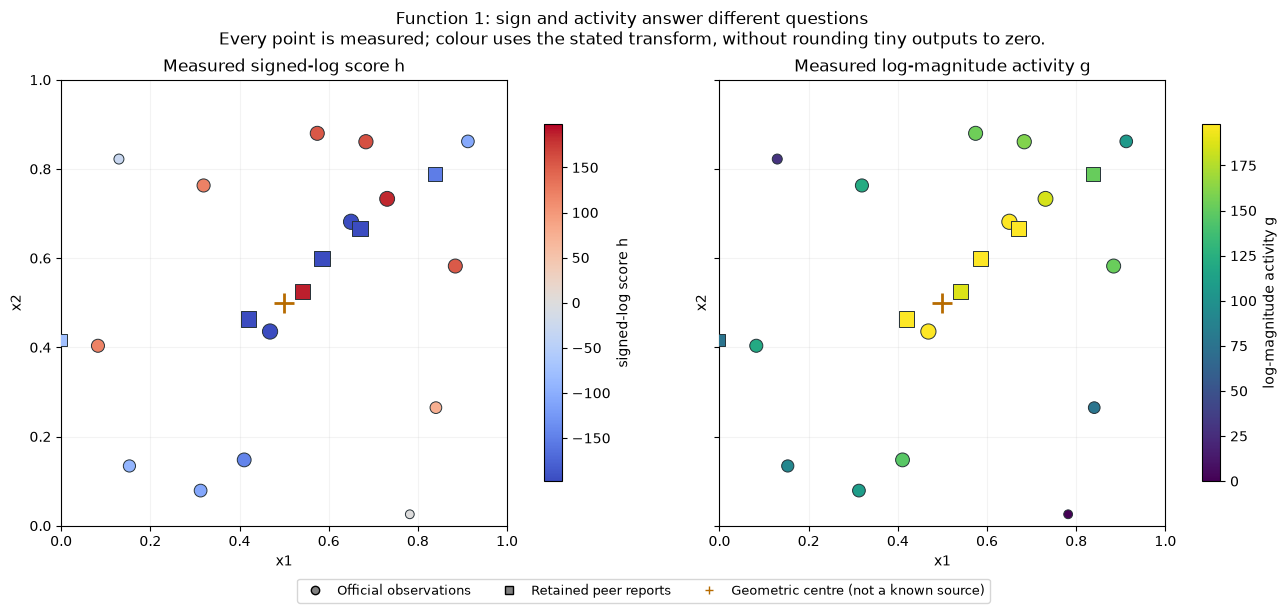

In [4]:
display(opposite_sign_pairs(pooled, input_columns=INPUT_COLUMNS).style.format({
    "positive_output":"{:.6e}", "negative_output":"{:.6e}", "input_distance":"{:.5f}"}))
display(plot_activity_evidence(pooled, scale=HEIGHT_SCALE, input_columns=INPUT_COLUMNS,
    save_to=OUTPUT_DIR / "measured-sign-and-activity.png"))


## 2. Hold the comparison settings fixed

Use the four existing GP families and the same MAE selection rule for each target. Official-only fits and peer-assisted fits are scored on the **same 15 official held-out rows**. Peer observations enter training only. Additional rows come from the unchanged, audited 20 October snapshot.

The first pool exactly follows the existing Week 6 broad/incumbent-local candidate construction. The second gives **both** policies the same extra neighbourhood around the strongest activity reading, plus the geometric centre and prepared signed point. Known official and peer inputs are excluded. Pool expansion is a sensitivity check, not a search for parameters that produce a central answer.


In [5]:
study = fit_activity_targets(official, pooled, input_columns=INPUT_COLUMNS,
    scale=HEIGHT_SCALE, fixed_settings=FIXED_SETTINGS, adaptive_settings=ADAPTIVE_SETTINGS,
    gp_names=GP_NAMES, selection_metric=SELECTION_METRIC)
activity_anchor = pooled.loc[pooled.y.abs().idxmax(), INPUT_COLUMNS].to_numpy(float)
pools = common_activity_pools(official[INPUT_COLUMNS].to_numpy(), pooled[INPUT_COLUMNS].to_numpy(),
    official.y.to_numpy(), input_columns=INPUT_COLUMNS, search_settings=SEARCH_SETTINGS,
    prepared_point=reference, centre=CENTRE, activity_anchor=activity_anchor)
policies = compare_activity_policies(study, pools, input_columns=INPUT_COLUMNS,
    reference=reference, gp_names=GP_NAMES, weights=WEIGHTS, main_weight=WEIGHT, centre=CENTRE)
assert study["studies"]["signed"]["selected"]["name"] == saved["query_model"]
assert study["studies"]["signed"]["selected"]["scope"] == saved["training_scope"]
np.testing.assert_allclose(study["studies"]["signed"]["selected"]["error"], saved["official_target_error"], rtol=1e-10)
np.testing.assert_array_equal(policies["proposals"]["baseline"]["signed"]["point"], reference)
print("Reproduced the existing signed-score GP choice and prepared point.")


Target: signed-log score h


Regression complete: Mean baseline; warnings=0


Regression complete: GP: local (l=0.15); warnings=0


Regression complete: GP: broad (l=0.35); warnings=0


Regression complete: Gaussian process; warnings=14


...

Peer-assisted official-target review complete: GP: local (l=0.15)


Peer-assisted official-target review complete: GP: broad (l=0.35)


Peer-assisted official-target review complete: Gaussian process


Peer-assisted official-target review complete: GP: separate length scales


Reproduced the existing signed-score GP choice and prepared point.


In [6]:
validation_rows = []
for name, run in study["studies"].items():
    selected = run["selected"]
    baseline = float(run["official"]["table"].set_index("Model").loc["Mean baseline", SELECTION_METRIC])
    validation_rows.append({"Target": TARGET_LABELS[name], "Selected GP": selected["name"],
        "Scope": selected["scope"], "Selected kernel": str(selected["model"].kernel_), "Official-target MAE": selected["error"],
        "Own-target mean-baseline MAE": baseline, "MAE / own baseline": selected["error"]/baseline})
display(pd.DataFrame(validation_rows))
for name, run in study["studies"].items():
    print(TARGET_LABELS[name])
    display(run["peers"]["table"])


,Target,Selected GP,Scope,Selected kernel,Official-target MAE,Own-target mean-baseline MAE,MAE / own baseline
0,signed-log score h,GP: separate length scales,official_plus_retained_peers,"0.962**2 * RBF(length_scale=[0.0738, 0.03])",119.636252,132.332213,0.904060
1,log-magnitude activity g,Gaussian process,official_plus_retained_peers,1.89**2 * RBF(length_scale=0.359),16.491898,47.369309,0.348156
2,absolute raw output |y|,GP: separate length scales,official_plus_retained_peers,"0.894**2 * RBF(length_scale=[0.267, 0.0366])",0.000846,0.001129,0.749850


signed-log score h


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,GP: local (l=0.15),158.045991,191.524220,123.174360,150.379288,0
1,GP: broad (l=0.35),222.348485,179.058919,157.072961,152.475755,0
2,Gaussian process,168.939069,137.609917,146.410261,119.779570,0
3,GP: separate length scales,171.984793,138.616776,148.382418,119.636252,13


log-magnitude activity g


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,GP: local (l=0.15),44.745764,44.700256,29.477132,27.145101,0
1,GP: broad (l=0.35),28.610896,25.058212,20.983550,17.573401,0
2,Gaussian process,31.485285,25.621076,22.456926,16.491898,0
3,GP: separate length scales,32.730014,28.068360,23.328257,18.443412,0


absolute raw output |y|


,Model,Official LOO RMSE,Peer-assisted LOO RMSE,Official LOO MAE,Peer-assisted LOO MAE,Fit warnings
0,GP: local (l=0.15),0.001519,0.001485,0.001066,0.001280,0
1,GP: broad (l=0.35),0.001875,0.001686,0.001567,0.001447,0
2,Gaussian process,0.001706,0.001031,0.001175,0.000973,0
3,GP: separate length scales,0.001730,0.001027,0.001192,0.000846,0


## 3. Does the proposed query move towards the centre?

The centre is the geometric reference $(0.5,0.5)$, not an assumed contamination source. Compare proposed locations and their Euclidean distances. The signed and magnitude policies use exactly the same candidate set within each comparison. Fitted means, SDs and UCB stay in each target's stated units.


,target,units,pool,model,training_scope,portal_input,predicted_target,latent_sd,ucb,distance_to_centre,reference_distance_to_centre,change_in_centre_distance,percent_closer_to_centre,movement_from_reference
0,signed,signed-log score h,baseline,GP: separate length scales,official_plus_retained_peers,0.608515-0.846200,118.110511,108.323915,330.425384,0.362808,0.362808,0.000000,0.000000,0.000000
1,magnitude,log-magnitude activity g,baseline,Gaussian process,official_plus_retained_peers,0.361195-0.379880,196.593192,6.343490,209.026432,0.183564,0.362808,-0.179245,49.404776,0.527846
2,raw_magnitude,absolute raw output |y|,baseline,GP: separate length scales,official_plus_retained_peers,0.590368-0.455132,0.005483,0.000938,0.007322,0.100894,0.362808,-0.261915,72.190950,0.391489
3,signed,signed-log score h,symmetric,GP: separate length scales,official_plus_retained_peers,0.608515-0.846200,118.110511,108.323915,330.425384,0.362808,0.362808,0.000000,0.000000,0.000000
4,magnitude,log-magnitude activity g,symmetric,Gaussian process,official_plus_retained_peers,0.354965-0.381615,196.341601,6.481307,209.044962,0.187217,0.362808,-0.175592,48.397868,0.529270
5,raw_magnitude,absolute raw output |y|,symmetric,GP: separate length scales,official_plus_retained_peers,0.590368-0.455132,0.005483,0.000938,0.007322,0.100894,0.362808,-0.261915,72.190950,0.391489


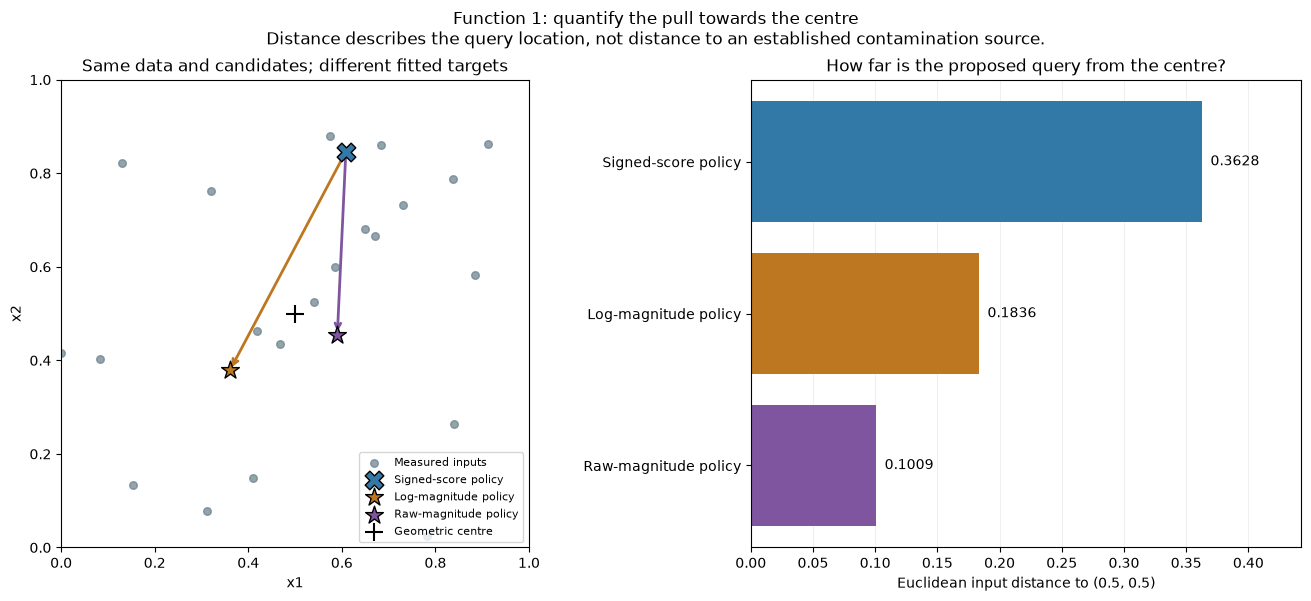

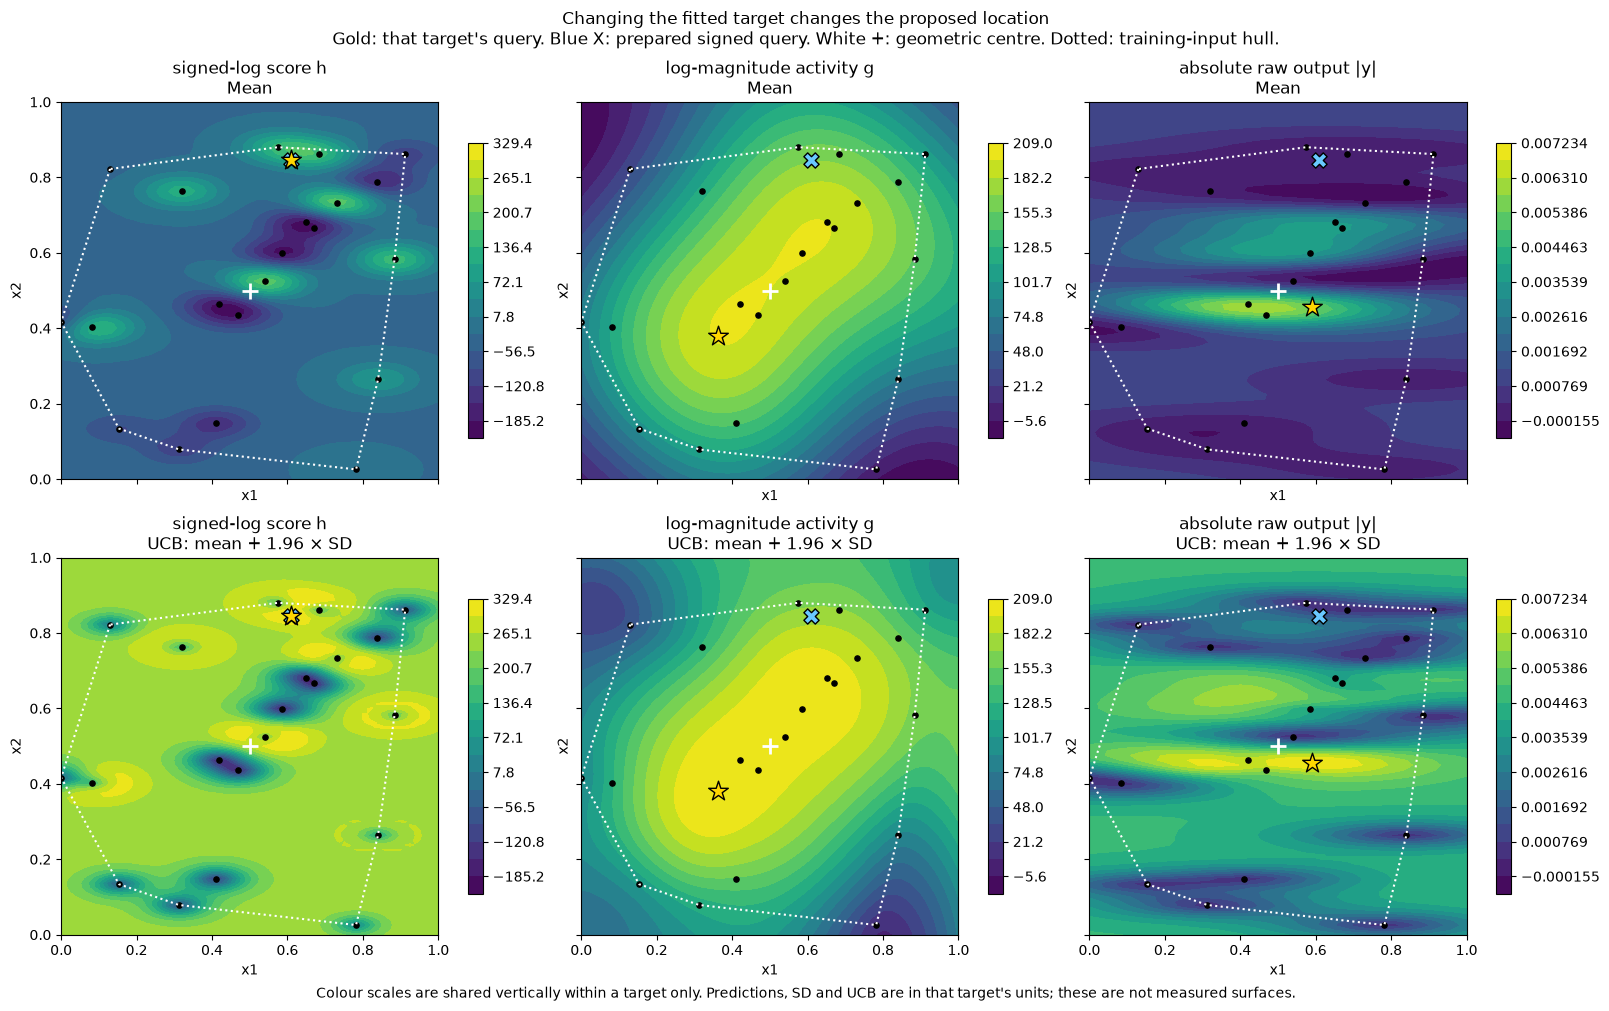

In [7]:
proposal_rows = [row for pool in policies["proposals"].values() for row in pool.values()]
display(pd.DataFrame(proposal_rows).drop(columns="point"))
display(plot_activity_query_shift(pooled, policies, input_columns=INPUT_COLUMNS, reference=reference,
    save_to=OUTPUT_DIR / "query-shift-towards-centre.png"))
display(plot_activity_decisions(study, policies, official, pooled, input_columns=INPUT_COLUMNS,
    reference=reference, weight=WEIGHT, save_to=OUTPUT_DIR / "target-decision-maps.png"))


## 4. Check model family, data scope and exploration weight

The same-family table changes the target while holding the GP family, training scope, candidate pool and exploration weight fixed. This distinguishes an activity effect from a different fitted model winning validation. The separate weight table uses 0, 1, 1.96 and 3; a central pull need not hold for every model or exploration preference.


In [8]:
controlled = policies["same_family_comparison"].pivot(index=["scope","model"], columns="target", values="distance_to_centre")
controlled["Log magnitude closer than signed"] = controlled.magnitude < controlled.signed
controlled["Raw magnitude closer than signed"] = controlled.raw_magnitude < controlled.signed
display(controlled)
display(policies["weight_sensitivity"])
# Cross-predict the actual hypothetical locations with every selected target fit.
cross_predictions = []
for point_label, row in policies["proposals"]["baseline"].items():
    for target_name, run in study["studies"].items():
        mean, sd = run["selected"]["model"].predict(np.asarray(row["point"])[None], return_std=True)
        cross_predictions.append({"Point policy": point_label, "Fitted target": TARGET_LABELS[target_name],
            "Mean": float(mean[0]), "Latent SD": float(sd[0])})
display(pd.DataFrame(cross_predictions))

# Separate the fitted mean preference from the uncertainty bonus.
mean_vs_ucb = policies["weight_sensitivity"].loc[lambda d: d.pool.eq("baseline") & d.weight.isin([0.,WEIGHT]), ["target","weight","x1","x2","distance_to_centre"]]
display(mean_vs_ucb)


target                               magnitude  raw_magnitude    signed  \
scope    model                                                            
official GP: broad (l=0.35)           0.091087       0.034941  0.512422   
         GP: local (l=0.15)           0.130487       0.066577  0.470616   
         GP: separate length scales   0.088141       0.088223  0.382096   
         Gaussian process             0.088141       0.088223  0.354955   
peers    GP: broad (l=0.35)           0.102733       0.127227  0.498771   
         GP: local (l=0.15)           0.235464       0.187809  0.707105   
         GP: separate length scales   0.190000       0.100894  0.362808   
         Gaussian process             0.187217       0.115854  0.391971   

target                               Log magnitude closer than signed  \
scope    model                                                          
official GP: broad (l=0.35)                                      True   
         GP: local (l=0.15)                                      True   
         GP: separate length scales                              True   
         Gaussian process                                        True   
peers    GP: broad (l=0.35)                                      True   
         GP: local (l=0.15)                                      True   
         GP: separate length scales                              True   
         Gaussian process                                        True   

target                               Raw magnitude closer than signed  
scope    model                                                         
official GP: broad (l=0.35)                                      True  
         GP: local (l=0.15)                                      True  
         GP: separate length scales                              True  
         Gaussian process                                        True  
peers    GP: broad (l=0.35)                                      True  
         GP: local (l=0.15)                                      True  
         GP: separate length scales                              True  
         Gaussian process                                        True

,pool,target,model,scope,weight,x1,x2,distance_to_centre,reference_distance_to_centre,change_in_centre_distance,percent_closer_to_centre,movement_from_reference
0,baseline,signed,GP: separate length scales,official_plus_retained_peers,0.00,0.537942,0.522217,0.043968,0.362808,-0.318840,87.881190,0.331580
1,baseline,signed,GP: separate length scales,official_plus_retained_peers,1.00,0.637838,0.879877,0.404111,0.362808,0.041303,-11.384182,0.044654
2,baseline,signed,GP: separate length scales,official_plus_retained_peers,1.96,0.608515,0.846200,0.362808,0.362808,0.000000,0.000000,0.000000
3,baseline,signed,GP: separate length scales,official_plus_retained_peers,3.00,0.595994,0.839376,0.352691,0.362808,-0.010117,2.788648,0.014260
4,baseline,magnitude,Gaussian process,official_plus_retained_peers,0.00,0.401359,0.426784,0.122844,0.362808,-0.239964,66.140828,0.467786
5,baseline,magnitude,Gaussian process,official_plus_retained_peers,1.00,0.377742,0.403998,0.155446,0.362808,-0.207363,57.154847,0.498797
6,baseline,magnitude,Gaussian process,official_plus_retained_peers,1.96,0.361195,0.379880,0.183564,0.362808,-0.179245,49.404776,0.527846
7,baseline,magnitude,Gaussian process,official_plus_retained_peers,3.00,0.340635,0.362578,0.210433,0.362808,-0.152376,41.998889,0.552856
8,baseline,raw_magnitude,GP: separate length scales,official_plus_retained_peers,0.00,0.449167,0.453403,0.068958,0.362808,-0.293850,80.993137,0.423888
9,baseline,raw_magnitude,GP: separate length scales,official_plus_retained_peers,1.00,0.509157,0.456552,0.044402,0.362808,-0.318406,87.761455,0.402116


,Point policy,Fitted target,Mean,Latent SD
0,signed,signed-log score h,118.110511,108.323915
1,signed,log-magnitude activity g,167.117817,3.936534
2,signed,absolute raw output |y|,0.000164,0.000693
3,magnitude,signed-log score h,-34.366346,139.046308
4,magnitude,log-magnitude activity g,196.593192,6.343490
5,magnitude,absolute raw output |y|,0.001090,0.001379
6,raw_magnitude,signed-log score h,-44.232687,136.021648
7,raw_magnitude,log-magnitude activity g,182.920377,7.277081
8,raw_magnitude,absolute raw output |y|,0.005483,0.000938


,target,weight,x1,x2,distance_to_centre
0,signed,0.00,0.537942,0.522217,0.043968
2,signed,1.96,0.608515,0.846200,0.362808
4,magnitude,0.00,0.401359,0.426784,0.122844
6,magnitude,1.96,0.361195,0.379880,0.183564
8,raw_magnitude,0.00,0.449167,0.453403,0.068958
10,raw_magnitude,1.96,0.590368,0.455132,0.100894


## 5. What this can justify

Strong negative values can reasonably motivate investigating an active region. Magnitude-guided sampling asks where a strong response might be learned about, regardless of sign. A negative lobe could be near a positive lobe, but that spatial relationship remains a hypothesis about this function.

The decision movement above can support a deliberate activity-led information query. It does not establish that the magnitude proposal will be positive, that a central maximum exceeds the confirmed best, or that the assignment writers intended a hidden sign rule. A positive outcome, or informative measurements near a sign transition, would be needed to test the nearby-positive-peak idea. Existing signed predictions at these locations remain visible in the cross-prediction table.


**An important qualification:** the signed model's mean-only candidate is already near the centre at approximately `(0.538, 0.522)`. Its prepared UCB point moves upwards because of the uncertainty bonus. At weight zero, magnitude does not produce the closest-to-centre proposal. The central pull demonstrated here concerns the current uncertainty-aware policy, and must not be generalised to every acquisition rule.

The magnitude fits are also more accurate relative to their own target baselines, but errors in different target units do not measure the same task. Sign changes are not assumed to be noise; the existing GP diagonal regularisation is retained without estimating a noise level.

In [9]:
result = {
    "function": 1, "week": 6, "analysis": "activity_hypothesis", "study_date": "2026-10-30",
    "official_rows": len(official), "retained_peer_rows": len(pooled)-len(official),
    "height_scale": HEIGHT_SCALE, "centre": list(CENTRE), "centre_is_a_source_estimate": False,
    "selection_metric": SELECTION_METRIC, "ucb_weight": WEIGHT,
    "candidate_counts": {name: len(pool) for name,pool in pools.items()},
    "reference_signed_proposal": reference.tolist(), "validation": validation_rows,
    "proposals": policies["proposals"], "weight_sensitivity": policies["weight_sensitivity"].to_dict(orient="records"),
    "same_family_comparison": policies["same_family_comparison"].to_dict(orient="records"),
    "cross_predictions": cross_predictions,
    "positive_peer_reports": pooled.loc[pooled.observation_id.str.startswith("peer-") & pooled.y.gt(0)].to_dict(orient="records"),
    "opposite_sign_pairs": opposite_sign_pairs(pooled,input_columns=INPUT_COLUMNS).to_dict(orient="records"),
    "warnings": {name:{"official":run["official"]["warnings"],"peers":run["peers"]["warnings"]}
                 for name,run in study["studies"].items()},
    "source_sha256": {str(p.relative_to(root)).replace("\\","/"):sha(p) for p in
        [DATA_PATH,COHORT_PATH,AUDIT_PATH,MODEL_REVIEW_PATH,function_shared/"function_1_activity_helpers.py"]},
    "prepared_submission_sha256": submission_before, "prepared_submission_changed":False,
    "new_course_evaluations":0, "portal_submission_performed":False,
}
assert sha(SUBMISSION_PATH) == submission_before
(OUTPUT_DIR/"results.json").write_text(json.dumps(result,indent=2,allow_nan=False)+"\n",encoding="utf-8")
print(json.dumps({"baseline_proposals":policies["proposals"]["baseline"],
                  "prepared_submission_changed":False},indent=2))


{
  "baseline_proposals": {
    "signed": {
      "target": "signed",
      "units": "signed-log score h",
      "pool": "baseline",
      "model": "GP: separate length scales",
      "training_scope": "official_plus_retained_peers",
      "point": [
        0.608515,
        0.8462
      ],
      "portal_input": "0.608515-0.846200",
      "predicted_target": 118.11051132172312,
      "latent_sd": 108.3239147844608,
      "ucb": 330.4253842992663,
      "distance_to_centre": 0.3628084139390926,
      "reference_distance_to_centre": 0.3628084139390926,
      "change_in_centre_distance": 0.0,
      "percent_closer_to_centre": 0.0,
      "movement_from_reference": 0.0
    },
    "magnitude": {
      "target": "magnitude",
      "units": "log-magnitude activity g",
      "pool": "baseline",
      "model": "Gaussian process",
      "training_scope": "official_plus_retained_peers",
      "point": [
        0.361195,
        0.37988
      ],
      "portal_input": "0.361195-0.379880",
      "p

## Course lifecycle

1. **Define the goal and scope** — test whether an activity target redirects the next query towards the centre, without approving submission.
2. **Gather the data** — use 15 official observations through round 5 and six unchanged retained peer reports.
3. **Explore the data** — show measured sign, magnitude and opposite-sign proximity in the input square.
4. **Clean and preprocess the data** — verify snapshots and audit hashes; preserve tiny non-zero values; declare signed-log, log-magnitude and raw absolute targets.
5. **Select and engineer features** — retain both original coordinates; the changed target is explicit and does not introduce a source-location feature.
6. **Define the machine-learning task** — compare regression-guided signed-score maximisation with an activity-led information heuristic.
7. **Partition the data** — reuse leave-one-out checks on identical official targets; peer rows enter training only. No independent final test is available.
8. **Select and train candidate methods** — separately fit the four declared GP families for each target; retain the existing validation criterion and tuning budget.
9. **Evaluate and interpret the results** — compare target-specific baselines, locations, centre distances, model/scoping controls, acquisition weights and cross-predictions.
10. **Deploy and iterate** — no deployment or submission applies; use the evidence in the continuing Function 1 discussion. The prepared file remains unchanged.
